# DS605: Lab-08 Decision Tree and SVM

### Part A: Decision Tree from Scratch
In this part, we implement a Decision Tree manually using NumPy and compare it with Scikit-learn. We use the Banknote Authentication dataset to classify banknotes into two classes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import plot_tree

# Load the Banknote Authentication dataset
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00267/"
    "data_banknote_authentication.txt"
)

columns = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
print(df.head())
print("\nClass distribution:")
print(df["class"].value_counts())
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


### Selecting Features and Splitting Data
We use variance and skewness for two-dimensional decision-boundary plots. We split the data into training and testing sets so we can evaluate predictions on unseen samples.

In [2]:
# Select two features for Part A visualizations
features = ["variance", "skewness"]

X = df[features].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])


Training samples: 960
Testing samples: 412
Number of features: 2


### Gini Impurity and Entropy
Gini impurity and entropy measure how mixed the classes are in a group. A group containing only one class has impurity zero, so the tree prefers splits that create purer groups.

In [3]:
def gini_impurity(y):
    """Calculate Gini impurity for a group of labels."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    """Calculate entropy for a group of labels."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


example_labels = np.array([0, 0, 1, 1])

print("Mixed group:")
print("Gini:", gini_impurity(example_labels))
print("Entropy:", entropy(example_labels))

pure_labels = np.array([1, 1, 1, 1])

print("\nPure group:")
print("Gini:", gini_impurity(pure_labels))
print("Entropy:", entropy(pure_labels))


Mixed group:
Gini: 0.5
Entropy: 1.0

Pure group:
Gini: 0.0
Entropy: -0.0


### Manual Decision Tree Implementation
We now build the tree without using Scikit-learn's tree algorithm. At each step, it searches for the feature and threshold that reduce impurity the most, then repeats this process recursively until a stopping condition is reached.

In [4]:
class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=2
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("Criterion must be 'gini' or 'entropy'.")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None

    def impurity(self, y):
        if self.criterion == "gini":
            return gini_impurity(y)
        return entropy(y)

    def best_split(self, X, y):
        parent_impurity = self.impurity(y)
        best_gain = 0.0
        best_feature = None
        best_threshold = None

        n_samples, n_features = X.shape

        for feature in range(n_features):
            values = np.unique(X[:, feature])

            if len(values) < 2:
                continue

            thresholds = (values[:-1] + values[1:]) / 2

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask

                if (
                    left_mask.sum() < self.min_samples_leaf
                    or right_mask.sum() < self.min_samples_leaf
                ):
                    continue

                y_left = y[left_mask]
                y_right = y[right_mask]

                weighted_impurity = (
                    len(y_left) / n_samples * self.impurity(y_left)
                    + len(y_right) / n_samples * self.impurity(y_right)
                )

                gain = parent_impurity - weighted_impurity

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_gain

    def build_tree(self, X, y, depth):
        # Stop when the node is pure or too small to split
        if (
            len(np.unique(y)) == 1
            or len(y) < self.min_samples_split
            or depth >= self.max_depth
        ):
            values, counts = np.unique(y, return_counts=True)
            return {"prediction": int(values[np.argmax(counts)])}

        feature, threshold, gain = self.best_split(X, y)

        # Stop if no useful split is found
        if feature is None or gain <= 1e-12:
            values, counts = np.unique(y, return_counts=True)
            return {"prediction": int(values[np.argmax(counts)])}

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        return {
            "feature": feature,
            "threshold": float(threshold),
            "gain": float(gain),
            "left": self.build_tree(
                X[left_mask], y[left_mask], depth + 1
            ),
            "right": self.build_tree(
                X[right_mask], y[right_mask], depth + 1
            )
        }

    def fit(self, X, y):
        self.root = self.build_tree(X, y, depth=0)
        return self

    def predict_one(self, sample):
        node = self.root

        while "prediction" not in node:
            feature = node["feature"]
            threshold = node["threshold"]

            if sample[feature] <= threshold:
                node = node["left"]
            else:
                node = node["right"]

        return node["prediction"]

    def predict(self, X):
        return np.array([self.predict_one(row) for row in X])

    def print_rules(self, node=None, depth=0, feature_names=None):
        if feature_names is None:
            feature_names = [f"feature_{i}" for i in range(2)]

        if node is None:
            node = self.root

        indent = "  " * depth

        if "prediction" in node:
            print(indent + f"Predict class {node['prediction']}")
            return

        feature_name = feature_names[node["feature"]]
        threshold = node["threshold"]

        print(f"{indent}IF {feature_name} <= {threshold:.4f}:")
        self.print_rules(node["left"], depth + 1, feature_names)

        print(f"{indent}ELSE:")
        self.print_rules(node["right"], depth + 1, feature_names)


### Training and Testing the Manual Tree
We train our own Decision Tree using the training data, predict the classes of unseen test samples, and measure its performance using accuracy, precision, recall, and F1-score.

In [5]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=2
)

manual_tree.fit(X_train, y_train)

y_pred_manual = manual_tree.predict(X_test)

print("Manual Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred_manual))
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_manual,
        zero_division=0
    )
)

print("\nLearned split rules:")
manual_tree.print_rules(feature_names=features)


Manual Decision Tree
Accuracy: 0.9320388349514563

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       229
           1       0.92      0.93      0.92       183

    accuracy                           0.93       412
   macro avg       0.93      0.93      0.93       412
weighted avg       0.93      0.93      0.93       412


Learned split rules:
IF variance <= 0.7683:
  IF skewness <= 5.3646:
    IF variance <= 0.3202:
      IF variance <= -0.2594:
        IF variance <= -1.7820:
          Predict class 1
        ELSE:
          Predict class 1
      ELSE:
        IF skewness <= -0.0300:
          Predict class 1
        ELSE:
          Predict class 1
    ELSE:
      IF skewness <= 3.2197:
        IF variance <= 0.7406:
          Predict class 0
        ELSE:
          Predict class 1
      ELSE:
        Predict class 1
  ELSE:
    IF variance <= -3.4311:
      IF variance <= -4.3819:
        Predict class 1
  

### Comparison with Scikit-learn
We train a Scikit-learn Decision Tree using the same training and testing data and similar settings. Comparing both models helps us check how our implementation performs against a standard implementation.

In [6]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

sklearn_tree.fit(X_train, y_train)

y_pred_sklearn = sklearn_tree.predict(X_test)

print("Model Comparison")
print("-" * 45)
print(
    "Manual Tree Accuracy:",
    round(accuracy_score(y_test, y_pred_manual), 4)
)
print(
    "Scikit-learn Tree Accuracy:",
    round(accuracy_score(y_test, y_pred_sklearn), 4)
)
print(
    "Predictions identical:",
    np.array_equal(y_pred_manual, y_pred_sklearn)
)

Model Comparison
---------------------------------------------
Manual Tree Accuracy: 0.932
Scikit-learn Tree Accuracy: 0.932
Predictions identical: True


### Visualizing the Learned Tree
We draw the manually constructed tree to see its decision questions, thresholds, and final class predictions. Each internal node represents a split, and each leaf represents a prediction.

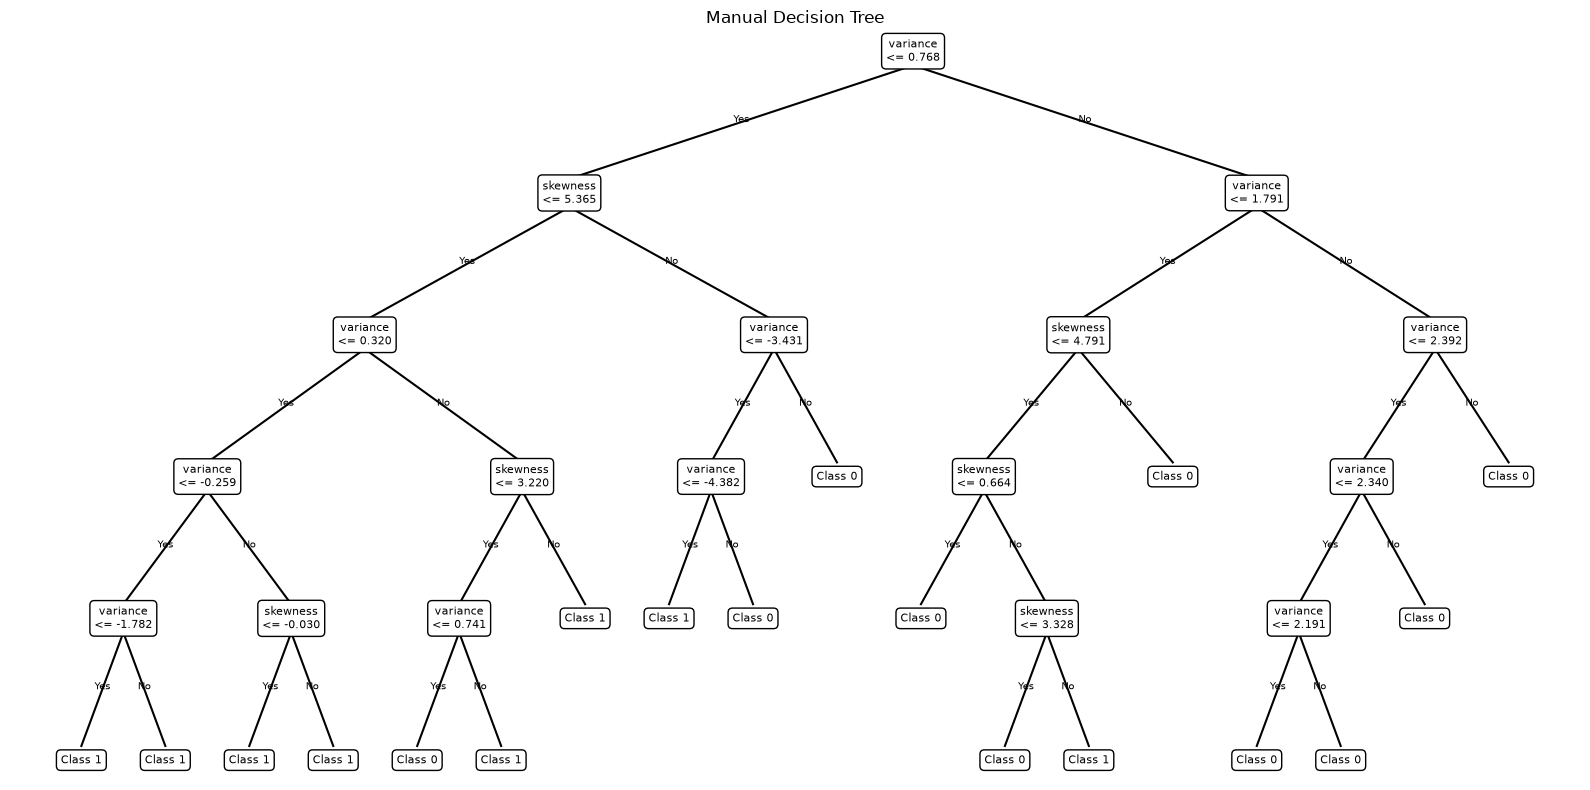

In [7]:
def count_leaves(node):
    if "prediction" in node:
        return 1
    return count_leaves(node["left"]) + count_leaves(node["right"])


def assign_positions(node, depth=0, positions=None):
    if positions is None:
        positions = [0]

    node["_y"] = depth

    if "prediction" in node:
        node["_x"] = positions[0]
        positions[0] += 1
    else:
        assign_positions(node["left"], depth + 1, positions)
        assign_positions(node["right"], depth + 1, positions)

        node["_x"] = (
            node["left"]["_x"] + node["right"]["_x"]
        ) / 2

    return node


def draw_manual_tree(ax, node, feature_names):
    x, y = node["_x"], node["_y"]

    if "prediction" in node:
        label = f"Class {node['prediction']}"
    else:
        label = (
            f"{feature_names[node['feature']]}\n"
            f"<= {node['threshold']:.3f}"
        )

    ax.text(
        x, -y, label,
        ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="black"),
        fontsize=8
    )

    if "prediction" not in node:
        for branch, condition in [
            ("left", "Yes"),
            ("right", "No")
        ]:
            child = node[branch]

            ax.plot(
                [x, child["_x"]],
                [-y - 0.1, -child["_y"] + 0.1],
                color="black"
            )

            ax.text(
                (x + child["_x"]) / 2,
                -(y + child["_y"]) / 2,
                condition,
                fontsize=7,
                ha="center"
            )

            draw_manual_tree(ax, child, feature_names)


assign_positions(manual_tree.root)

fig, ax = plt.subplots(figsize=(16, 8))
draw_manual_tree(ax, manual_tree.root, features)

ax.set_title("Manual Decision Tree")
ax.axis("off")
plt.tight_layout()
plt.show()


### Decision Boundary Visualization
A decision boundary shows which regions the model classifies as class 0 or class 1. We plot the manual tree and Scikit-learn tree using variance and skewness, while the test samples show how the classes are distributed.

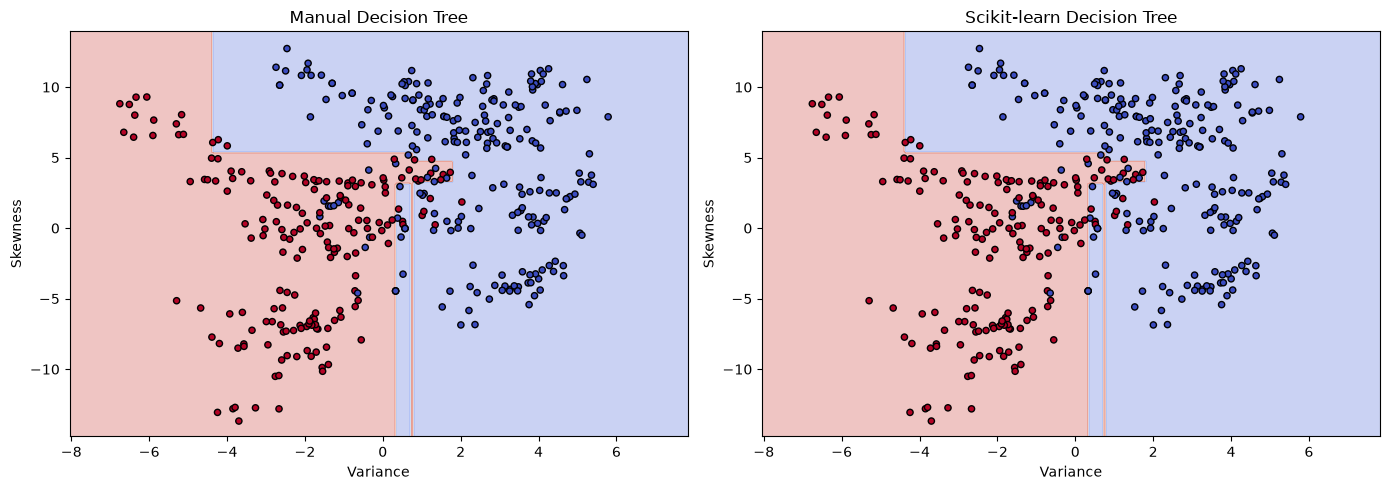

In [8]:
# Create a grid covering the feature space
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Predict the class at every point on the grid
Z_manual = manual_tree.predict(grid).reshape(xx.shape)
Z_sklearn = sklearn_tree.predict(grid).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (axes[0], Z_manual, "Manual Decision Tree"),
    (axes[1], Z_sklearn, "Scikit-learn Decision Tree")
]

for ax, Z, title in models:
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(
        X_test[:, 0], X_test[:, 1],
        c=y_test, cmap="coolwarm",
        edgecolors="black", s=20
    )
    ax.set_xlabel("Variance")
    ax.set_ylabel("Skewness")
    ax.set_title(title)

plt.tight_layout()
plt.show()


### Scikit-learn Tree Visualization
We visualize the Scikit-learn tree to compare its split rules with our manually implemented tree. Both models use the same two features and training data.

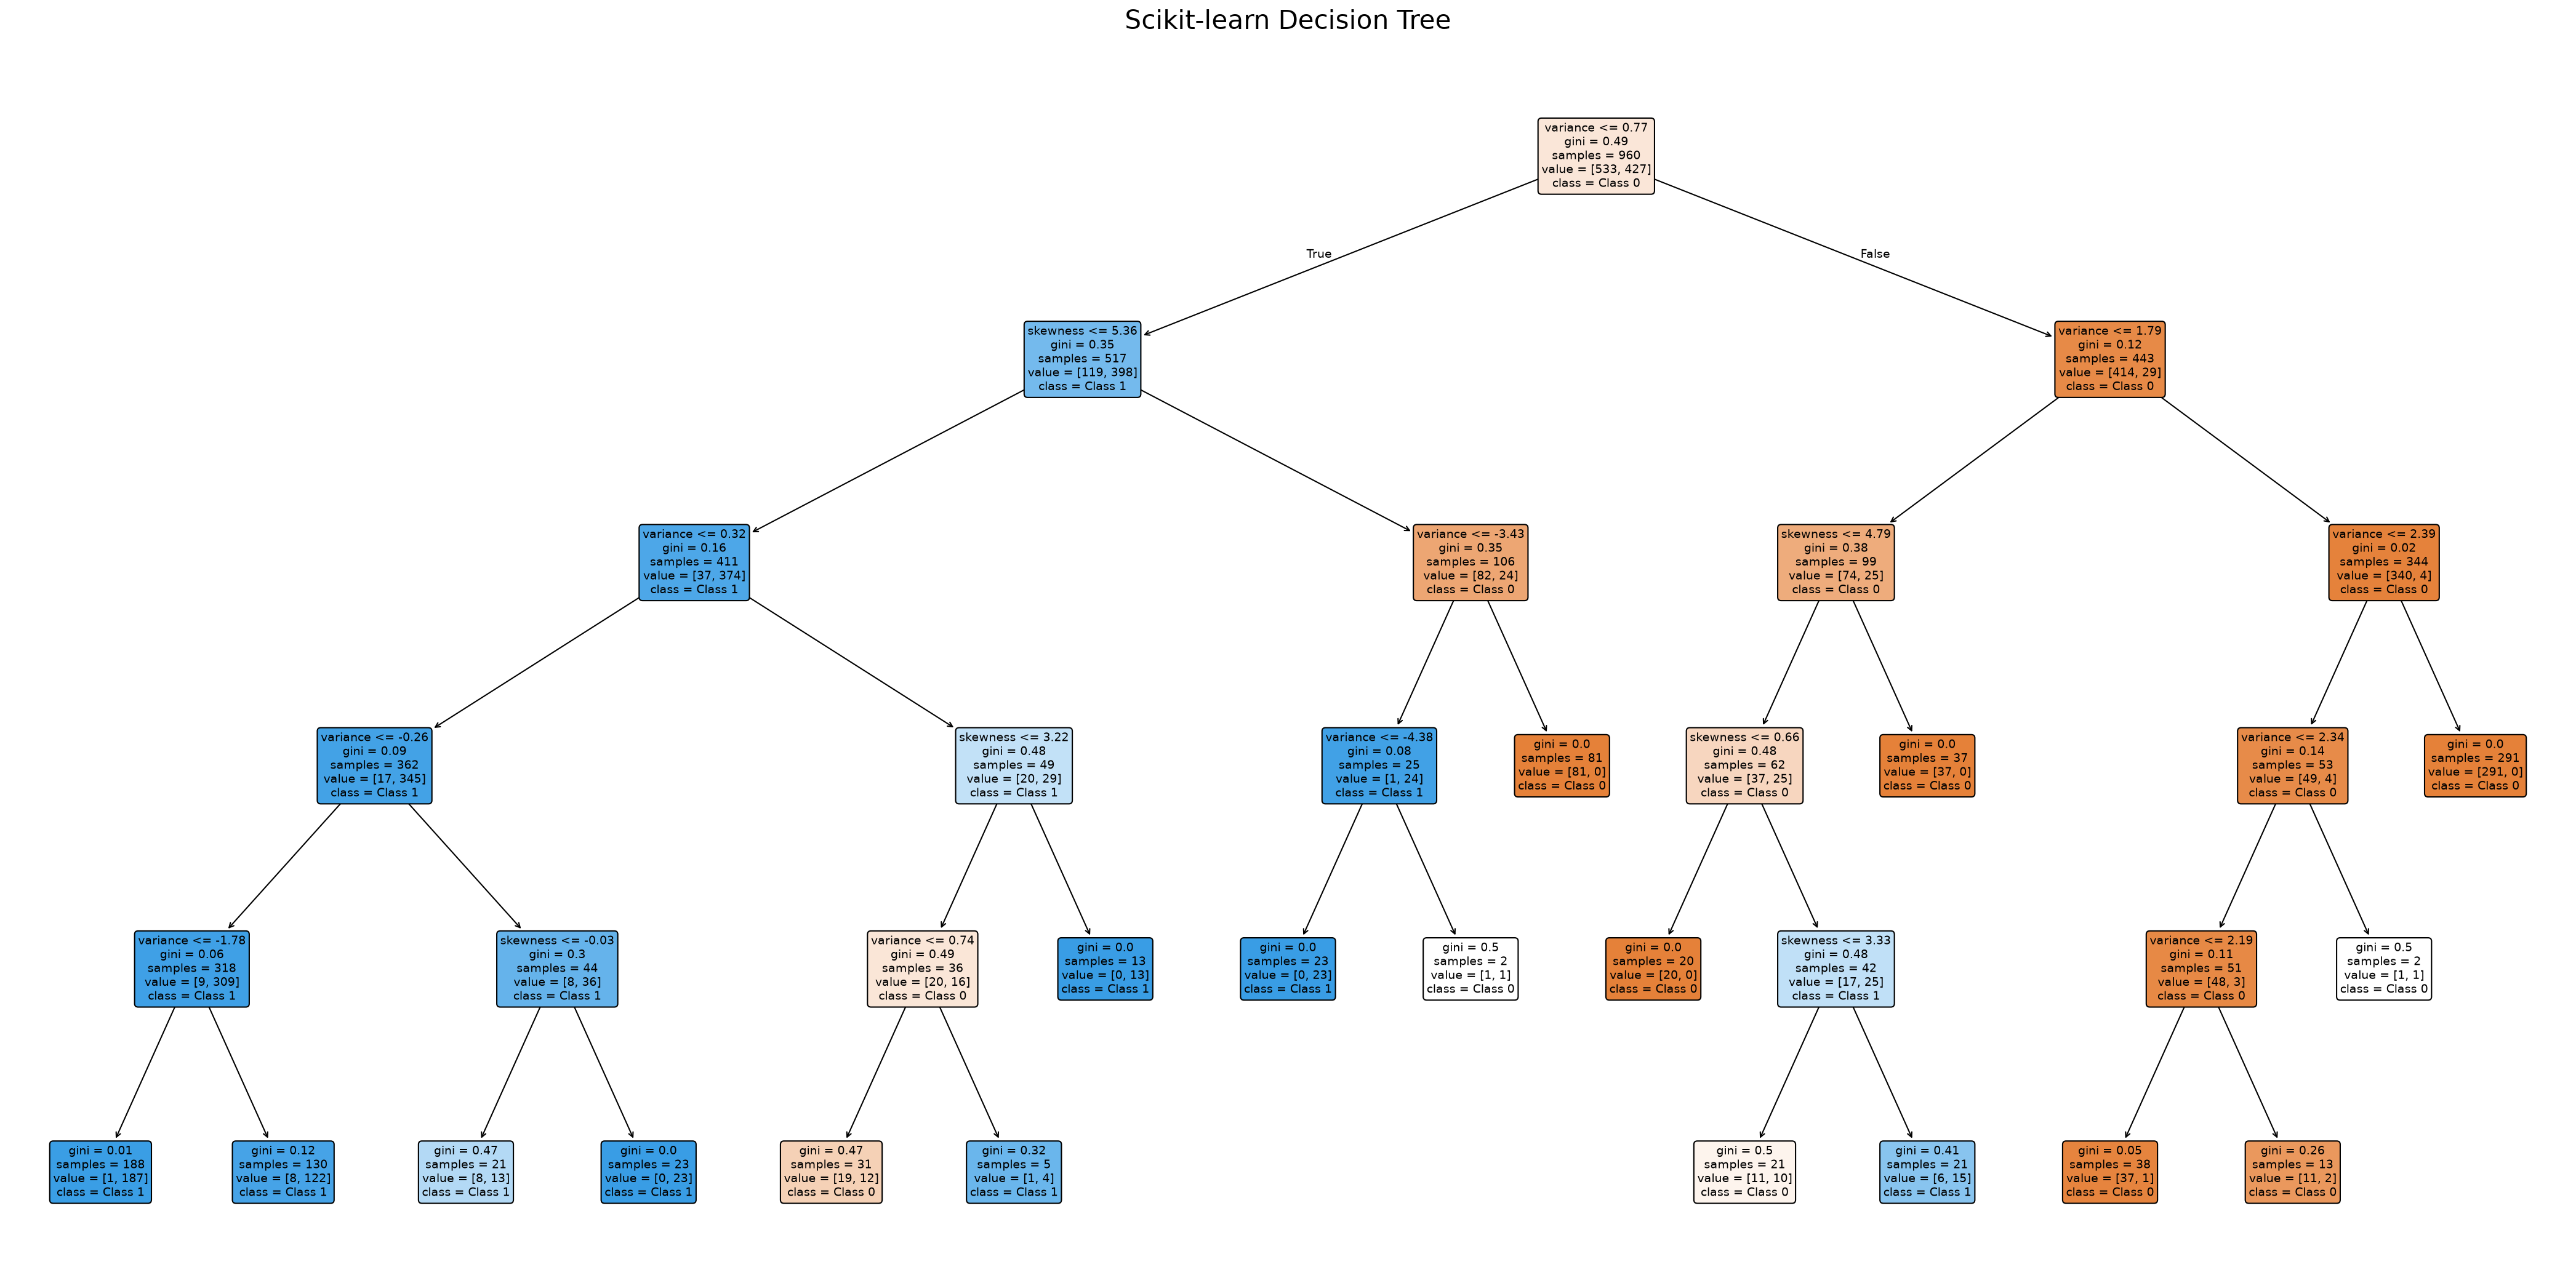

In [9]:
# Visualize the Scikit-learn Decision Tree more clearly

plt.figure(figsize=(28, 14), dpi=150)

plot_tree(
    sklearn_tree,
    feature_names=features,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=9
)

plt.title("Scikit-learn Decision Tree", fontsize=20, pad=20)
plt.tight_layout()
plt.savefig("sklearn_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


### Effect of Splitting Criterion and Tree Depth
We train models using both Gini impurity and entropy at different maximum depths. This helps us understand how the splitting criterion and tree complexity affect test accuracy.

In [10]:
results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8]:
        # Our manual implementation
        manual = ManualDecisionTree(
            criterion=criterion,
            max_depth=depth,
            min_samples_leaf=2
        )
        manual.fit(X_train, y_train)
        manual_pred = manual.predict(X_test)

        # Scikit-learn implementation
        standard = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            min_samples_leaf=2,
            random_state=42
        )
        standard.fit(X_train, y_train)
        standard_pred = standard.predict(X_test)

        results.append({
            "Criterion": criterion,
            "Max Depth": depth,
            "Manual Accuracy": accuracy_score(
                y_test, manual_pred
            ),
            "Scikit-learn Accuracy": accuracy_score(
                y_test, standard_pred
            ),
            "Identical Predictions": np.array_equal(
                manual_pred, standard_pred
            )
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


Criterion  Max Depth  Manual Accuracy  Scikit-learn Accuracy  Identical Predictions
     gini          2           0.8738                 0.8738                   True
     gini          3           0.9126                 0.9126                   True
     gini          5           0.9320                 0.9320                   True
     gini          8           0.9199                 0.9199                   True
  entropy          2           0.8738                 0.8738                   True
  entropy          3           0.9126                 0.9126                   True
  entropy          5           0.9248                 0.9248                   True
  entropy          8           0.9296                 0.9296                   True


### Observations

The manual Decision Tree produced the same predictions as the Scikit-learn Decision Tree in all eight experiments. With the Gini criterion, the highest test accuracy was 93.20% at a maximum depth of 5. Increasing the depth to 8 reduced the accuracy to 91.99%. With entropy, the highest accuracy was 92.96% at depth 8. These results show that the splitting criterion and maximum depth can affect test performance, and a deeper tree does not necessarily provide better predictions.

## Part B: Linear SVM from Scratch
SVM works better when features are on comparable scales. We standardize the features using training-set statistics and convert the binary labels from 0/1 to -1/+1, as required for our manual SVM.

In [11]:
# Calculate scaling values using only training data
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

# Avoid division by zero if a feature has no variation
X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Convert labels: class 0 -> -1, class 1 -> +1
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("SVM training labels:", np.unique(y_train_svm))
print("SVM testing labels:", np.unique(y_test_svm))


Scaled training shape: (960, 2)
Scaled testing shape: (412, 2)
SVM training labels: [-1  1]
SVM testing labels: [-1  1]


### Implementing a Linear SVM
The SVM learns weights and a bias to separate the two classes. We use hinge loss to penalize incorrect predictions and samples that fall inside the margin, together with gradient/subgradient descent to update the parameters.

In [12]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.01, iterations=5000):
        self.C = C
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.iterations):
            # Signed margin: y * (w.x + b)
            margins = y * (X @ self.w + self.b)

            # Samples with margin < 1 contribute hinge-loss gradient
            violating = margins < 1

            # Gradient of regularization + mean hinge loss
            grad_w = self.w - self.C * (
                X[violating].T @ y[violating]
            ) / n_samples

            grad_b = -self.C * np.sum(y[violating]) / n_samples

            # Update weights and bias
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            # Record objective value for monitoring
            hinge = np.maximum(0, 1 - y * (X @ self.w + self.b))
            loss = (
                0.5 * np.dot(self.w, self.w)
                + self.C * np.mean(hinge)
            )
            self.loss_history.append(loss)

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


### Training and Evaluating the Manual SVM
We train the manual SVM on scaled training data and evaluate it on scaled test data. We report accuracy and a classification report to measure how well it distinguishes the two banknote classes.

In [13]:
from sklearn.metrics import accuracy_score, classification_report

manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    iterations=5000
)

manual_svm.fit(X_train_scaled, y_train_svm)

y_pred_manual_svm = manual_svm.predict(X_test_scaled)

print("Manual Linear SVM")
print("Accuracy:", accuracy_score(y_test_svm, y_pred_manual_svm))
print("\nClassification Report:")
print(
    classification_report(
        y_test_svm,
        y_pred_manual_svm,
        labels=[-1, 1],
        target_names=["Class 0", "Class 1"],
        zero_division=0
    )
)

print("Learned weights:", manual_svm.w)
print("Learned bias:", manual_svm.b)


Manual Linear SVM
Accuracy: 0.8616504854368932

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.83      0.95      0.88       229
     Class 1       0.93      0.75      0.83       183

    accuracy                           0.86       412
   macro avg       0.88      0.85      0.86       412
weighted avg       0.87      0.86      0.86       412

Learned weights: [-0.4986235  -0.24993208]
Learned bias: -0.2882604166666716


### Visualizing the SVM Boundary and Margins
The decision boundary is where the SVM score equals zero. The two margin lines have scores +1 and -1; samples with a signed margin below 1 violate the margin condition.

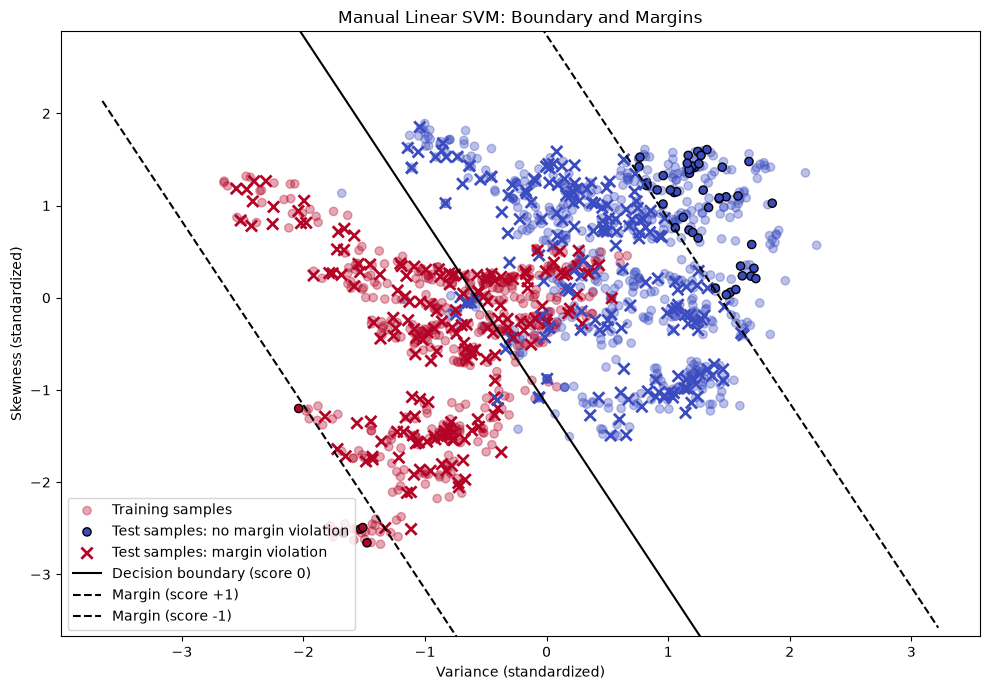

Test samples violating the margin: 362
Total test samples: 412


In [14]:
# Calculate each test sample's signed margin
test_scores = manual_svm.decision_function(X_test_scaled)
test_margins = y_test_svm * test_scores
violating_mask = test_margins < 1

# Plot in scaled feature space
x_min = X_train_scaled[:, 0].min() - 1
x_max = X_train_scaled[:, 0].max() + 1
x_values = np.linspace(x_min, x_max, 300)

w1, w2 = manual_svm.w

if abs(w2) < 1e-10:
    print("Cannot draw the lines as y = f(x) because w2 is near zero.")
else:
    # w1*x + w2*y + b = score
    boundary = -(w1 * x_values + manual_svm.b) / w2
    margin_positive = (1 - w1 * x_values - manual_svm.b) / w2
    margin_negative = (-1 - w1 * x_values - manual_svm.b) / w2

    plt.figure(figsize=(10, 7))

    # Training samples show the data used to learn the boundary
    plt.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=y_train_svm,
        cmap="coolwarm",
        alpha=0.35,
        label="Training samples"
    )

    # Highlight test samples that violate the margin
    plt.scatter(
        X_test_scaled[~violating_mask, 0],
        X_test_scaled[~violating_mask, 1],
        c=y_test_svm[~violating_mask],
        cmap="coolwarm",
        edgecolors="black",
        s=35,
        label="Test samples: no margin violation"
    )

    plt.scatter(
        X_test_scaled[violating_mask, 0],
        X_test_scaled[violating_mask, 1],
        c=y_test_svm[violating_mask],
        cmap="coolwarm",
        marker="x",
        s=65,
        linewidths=2,
        label="Test samples: margin violation"
    )

    plt.plot(x_values, boundary, color="black", label="Decision boundary (score 0)")
    plt.plot(x_values, margin_positive, "k--", label="Margin (score +1)")
    plt.plot(x_values, margin_negative, "k--", label="Margin (score -1)")

    plt.ylim(
        X_train_scaled[:, 1].min() - 1,
        X_train_scaled[:, 1].max() + 1
    )
    plt.xlabel("Variance (standardized)")
    plt.ylabel("Skewness (standardized)")
    plt.title("Manual Linear SVM: Boundary and Margins")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Test samples violating the margin:", violating_mask.sum())
    print("Total test samples:", len(y_test_svm))


### Comparing Manual and Scikit-learn SVMs
We train Scikit-learn's linear SVM on the same scaled data and compare test accuracy. This helps us evaluate our manual implementation against a standard implementation.

In [15]:
from sklearn.svm import SVC

sklearn_svm = SVC(kernel="linear", C=1.0)
sklearn_svm.fit(X_train_scaled, y_train_svm)

y_pred_sklearn_svm = sklearn_svm.predict(X_test_scaled)

print("Linear SVM Comparison")
print("-" * 40)
print(
    "Manual SVM Accuracy:",
    round(accuracy_score(y_test_svm, y_pred_manual_svm), 4)
)
print(
    "Scikit-learn SVM Accuracy:",
    round(accuracy_score(y_test_svm, y_pred_sklearn_svm), 4)
)
print(
    "Identical predictions:",
    np.array_equal(y_pred_manual_svm, y_pred_sklearn_svm)
)


Linear SVM Comparison
----------------------------------------
Manual SVM Accuracy: 0.8617
Scikit-learn SVM Accuracy: 0.8811
Identical predictions: False


### Observations: Manual vs. Scikit-learn Linear SVM

The manual Linear SVM achieved 86.17% test accuracy, while Scikit-learn's Linear SVM achieved 88.11%. Their predictions were not identical. This difference may arise from the optimization procedure and convergence behavior of the manual implementation. Both models use the same scaled features and train-test split, allowing a fair comparison of their predictive performance.

### Visualizing the Scikit-learn SVM
We plot the Scikit-learn SVM decision boundary beside the manual SVM boundary. This lets us visually compare how each implementation separates the two classes.

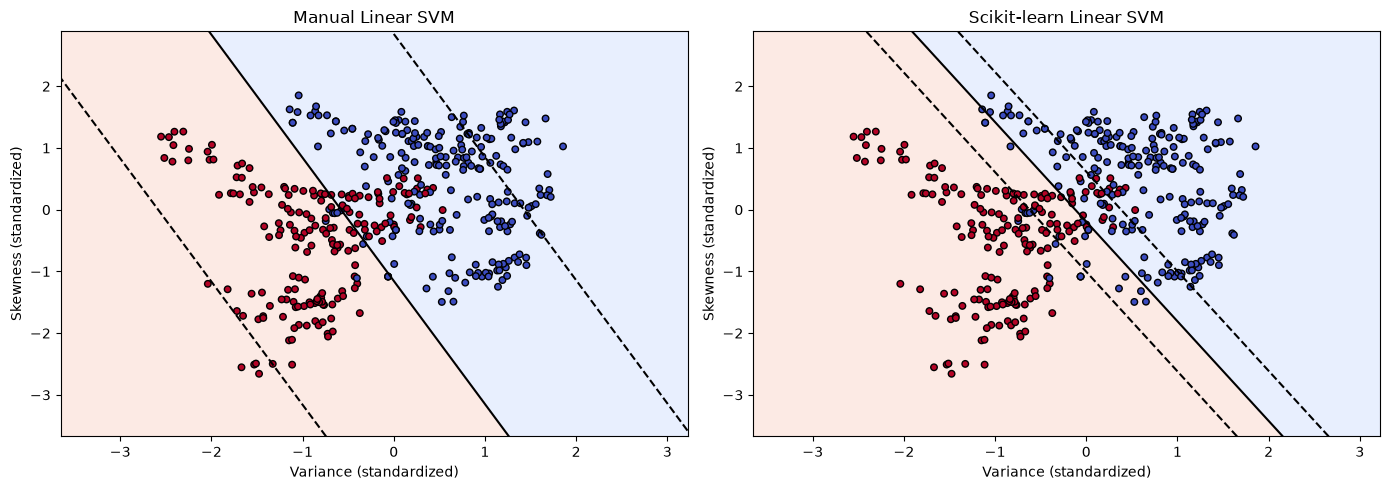

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (axes[0], manual_svm, "Manual Linear SVM"),
    (axes[1], sklearn_svm, "Scikit-learn Linear SVM")
]

for ax, model, title in models:
    scores = model.decision_function(
        np.c_[xx.ravel(), yy.ravel()]
        if False else
        np.c_[np.zeros(1), np.zeros(1)]
    ) if False else None

    # Create a grid in standardized feature space
    gx_min = X_train_scaled[:, 0].min() - 1
    gx_max = X_train_scaled[:, 0].max() + 1
    gy_min = X_train_scaled[:, 1].min() - 1
    gy_max = X_train_scaled[:, 1].max() + 1

    gx, gy = np.meshgrid(
        np.linspace(gx_min, gx_max, 250),
        np.linspace(gy_min, gy_max, 250)
    )
    grid_scaled = np.c_[gx.ravel(), gy.ravel()]
    grid_scores = model.decision_function(grid_scaled).reshape(gx.shape)

    ax.contourf(gx, gy, grid_scores >= 0, alpha=0.2, cmap="coolwarm")
    ax.contour(gx, gy, grid_scores, levels=[0], colors="black")
    ax.contour(
        gx, gy, grid_scores,
        levels=[-1, 1],
        colors="black",
        linestyles="dashed"
    )

    ax.scatter(
        X_test_scaled[:, 0],
        X_test_scaled[:, 1],
        c=y_test_svm,
        cmap="coolwarm",
        edgecolors="black",
        s=22
    )

    ax.set_xlabel("Variance (standardized)")
    ax.set_ylabel("Skewness (standardized)")
    ax.set_title(title)

plt.tight_layout()
plt.show()


### Studying SVM Hyperparameters
The regularization parameter \(C\) controls the trade-off between a wider margin and penalizing margin violations. We vary \(C\), learning rate, and iterations to observe how these settings affect the manual model's test accuracy.

In [17]:
experiment_results = []

settings = [
    (0.1, 0.01, 5000),
    (1.0, 0.01, 5000),
    (10.0, 0.01, 5000),
    (1.0, 0.001, 5000),
    (1.0, 0.01, 1000),
    (1.0, 0.01, 10000)
]

for C_value, lr_value, iteration_value in settings:
    model = ManualLinearSVM(
        C=C_value,
        learning_rate=lr_value,
        iterations=iteration_value
    )

    model.fit(X_train_scaled, y_train_svm)
    predictions = model.predict(X_test_scaled)

    experiment_results.append({
        "C": C_value,
        "Learning Rate": lr_value,
        "Iterations": iteration_value,
        "Test Accuracy": accuracy_score(
            y_test_svm, predictions
        )
    })

svm_results_df = pd.DataFrame(experiment_results)

print(svm_results_df.to_string(index=False))


   C  Learning Rate  Iterations  Test Accuracy
 0.1          0.010        5000       0.555825
 1.0          0.010        5000       0.861650
10.0          0.010        5000       0.890777
 1.0          0.001        5000       0.864078
 1.0          0.010        1000       0.861650
 1.0          0.010       10000       0.861650


### Comparison of Linear SVM Decision Boundaries

The plots show the decision boundaries and margins learned by the manual Linear SVM and Scikit-learn Linear SVM. Both models learn a similar diagonal separation between the two classes, but their boundaries differ slightly due to differences in their optimization procedures. Some samples fall within the margins or on the incorrect side of the decision boundary, which is permitted by a soft-margin SVM. The manual model achieved 86.17% test accuracy, compared with 88.11% for Scikit-learn.

## Part C: Nonlinear SVM using Different Kernels

In this part, we create a two-dimensional dataset with nonlinear class patterns. We then train SVM models using linear, polynomial, and RBF kernels to compare how they separate the classes.

### Creating a Nonlinear Dataset

We use `make_moons()` to generate a synthetic dataset containing two classes arranged in curved, moon-like shapes. This dataset helps us compare how linear and nonlinear SVM kernels separate data.

In [18]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Generate a nonlinear dataset
X_nonlinear, y_nonlinear = make_moons(
    n_samples=1000,
    noise=0.20,
    random_state=42
)

# Split into 70% training and 30% testing data
X_nl_train, X_nl_test, y_nl_train, y_nl_test = train_test_split(
    X_nonlinear,
    y_nonlinear,
    test_size=0.30,
    random_state=42,
    stratify=y_nonlinear
)

print("Complete dataset shape:", X_nonlinear.shape)
print("Training features shape:", X_nl_train.shape)
print("Testing features shape:", X_nl_test.shape)
print("Training labels shape:", y_nl_train.shape)
print("Testing labels shape:", y_nl_test.shape)


Complete dataset shape: (1000, 2)
Training features shape: (700, 2)
Testing features shape: (300, 2)
Training labels shape: (700,)
Testing labels shape: (300,)


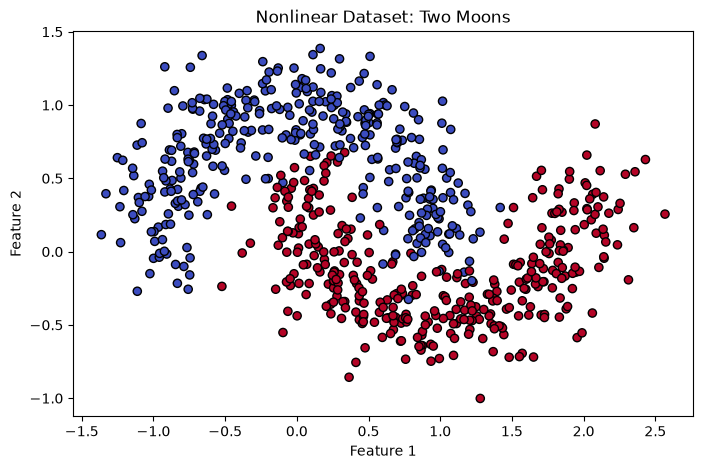

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.figure(figsize=(8, 5))

plt.scatter(
    X_nl_train[:, 0],
    X_nl_train[:, 1],
    c=y_nl_train,
    cmap="coolwarm",
    edgecolors="black",
    s=35
)

plt.title("Nonlinear Dataset: Two Moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


### Training SVM Models with Different Kernels

An SVM kernel helps the model learn different types of decision boundaries.

- **Linear kernel:** Creates a straight decision boundary.
- **Polynomial kernel:** Can create curved boundaries using polynomial relationships between features.
- **RBF (Radial Basis Function) kernel:** Can learn flexible, nonlinear boundaries based on the similarity between data points.

In [20]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Define the three SVM models
svm_models = {
    "Linear": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0)
    ),
    "Polynomial": make_pipeline(
        StandardScaler(),
        SVC(kernel="poly", degree=3, C=1.0)
    ),
    "RBF": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    )
}

# Train and evaluate each model
for name, model in svm_models.items():
    model.fit(X_nl_train, y_nl_train)
    predictions = model.predict(X_nl_test)
    accuracy = accuracy_score(y_nl_test, predictions)

    print(f"{name} SVM Test Accuracy: {accuracy:.4f}")


Linear SVM Test Accuracy: 0.8933
Polynomial SVM Test Accuracy: 0.8933
RBF SVM Test Accuracy: 0.9867


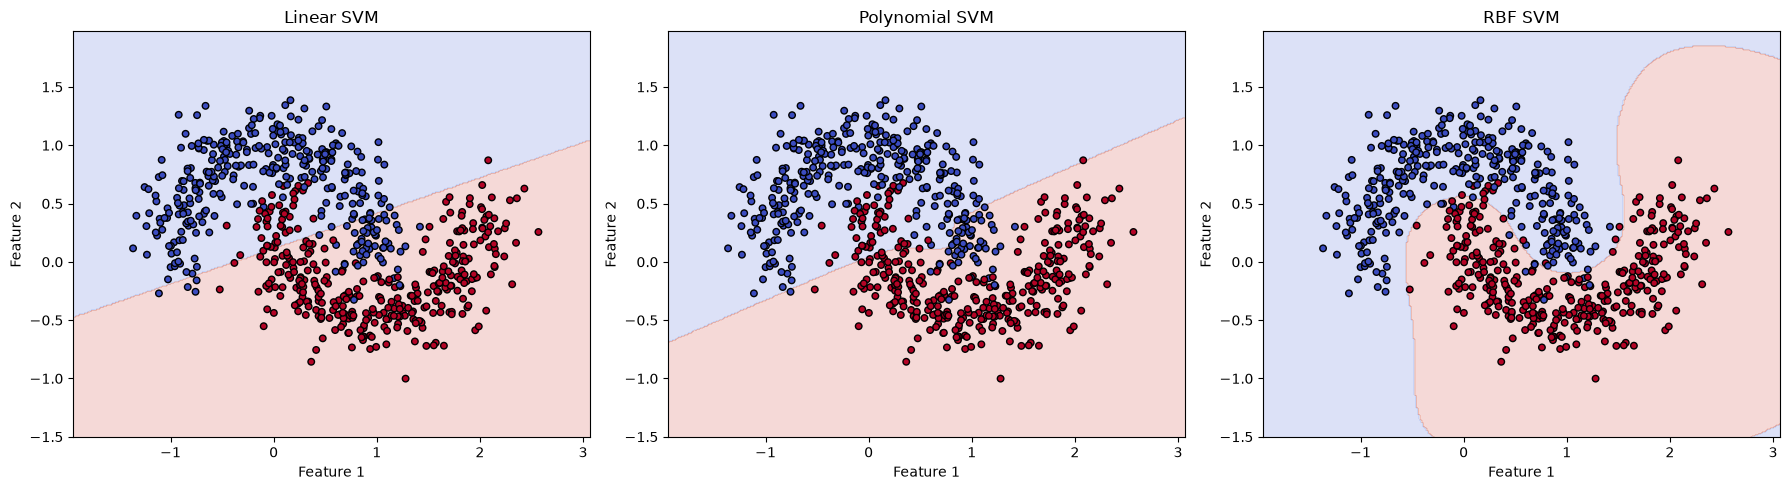

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x_min, x_max = X_nonlinear[:, 0].min() - 0.5, X_nonlinear[:, 0].max() + 0.5
y_min, y_max = X_nonlinear[:, 1].min() - 0.5, X_nonlinear[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

for ax, (name, model) in zip(axes, svm_models.items()):
    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        alpha=0.20,
        cmap="coolwarm"
    )

    ax.scatter(
        X_nl_train[:, 0],
        X_nl_train[:, 1],
        c=y_nl_train,
        cmap="coolwarm",
        edgecolors="black",
        s=22
    )

    ax.set_title(f"{name} SVM")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


In [22]:
results_part_c_df = pd.DataFrame(results_part_c)

results_part_c_df = results_part_c_df.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

results_part_c_df


NameError: name 'results_part_c' is not defined

### Observations

The linear kernel produces a straight decision boundary and may not capture the curved structure of the two-moons dataset effectively. The polynomial kernel can learn curved boundaries, while the RBF kernel can model more flexible nonlinear patterns. Comparing their test accuracies helps us understand which kernel separates this dataset most effectively. A more complex boundary is not automatically better, as excessive flexibility may lead to overfitting.

## Part D: Final Model Comparison

In this part, we compare five models on the original Banknote Authentication dataset using all four features: variance, skewness, curtosis, and entropy. We use the same training and testing split for every model so their performance can be compared fairly.

In [27]:
# Load the original Banknote Authentication dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

banknote_df = pd.read_csv(
    url,
    header=None,
    names=["variance", "skewness", "curtosis", "entropy", "class"]
)

# Use all four features
X_full = banknote_df[
    ["variance", "skewness", "curtosis", "entropy"]
].values

y_full = banknote_df["class"].values

# Use the same 70-30 split for all models
X_full_train, X_full_test, y_full_train, y_full_test = train_test_split(
    X_full,
    y_full,
    test_size=0.30,
    random_state=42,
    stratify=y_full
)

print("Complete dataset:", X_full.shape)
print("Training features:", X_full_train.shape)
print("Testing features:", X_full_test.shape)
print("Training labels:", y_full_train.shape)
print("Testing labels:", y_full_test.shape)


Complete dataset: (1372, 4)
Training features: (960, 4)
Testing features: (412, 4)
Training labels: (960,)
Testing labels: (412,)


### Training Decision Tree Models

We train the manual Decision Tree and Scikit-learn Decision Tree using all four features. Both models use the Gini criterion and a maximum depth of 5, allowing us to compare their predictions under the same settings.

In [28]:
from sklearn.tree import DecisionTreeClassifier

# Train the manual Decision Tree
manual_tree_full = ManualDecisionTree(
    criterion="gini",
    max_depth=5
)

manual_tree_full.fit(X_full_train, y_full_train)
manual_tree_pred = manual_tree_full.predict(X_full_test)

# Train the Scikit-learn Decision Tree
sklearn_tree_full = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_tree_full.fit(X_full_train, y_full_train)
sklearn_tree_pred = sklearn_tree_full.predict(X_full_test)

print("Manual Tree Accuracy:",
      accuracy_score(y_full_test, manual_tree_pred))

print("Scikit-learn Tree Accuracy:",
      accuracy_score(y_full_test, sklearn_tree_pred))

print("Identical predictions:",
      np.array_equal(manual_tree_pred, sklearn_tree_pred))


Manual Tree Accuracy: 0.9830097087378641
Scikit-learn Tree Accuracy: 0.9854368932038835
Identical predictions: False


### Training Linear SVM Models

SVM models are sensitive to feature scales, so we standardize the four features using training-set statistics. We then train the manual Linear SVM and Scikit-learn Linear SVM on the same scaled data.

In [29]:
# Standardize using training-set statistics only
full_mean = X_full_train.mean(axis=0)
full_std = X_full_train.std(axis=0)
full_std[full_std == 0] = 1

X_full_train_scaled = (X_full_train - full_mean) / full_std
X_full_test_scaled = (X_full_test - full_mean) / full_std

# Convert class labels from 0/1 to -1/+1 for the manual SVM
y_full_train_svm = np.where(y_full_train == 0, -1, 1)

# Train the manual Linear SVM
manual_svm_full = ManualLinearSVM(
    C=10.0,
    learning_rate=0.01,
    iterations=5000
)

manual_svm_full.fit(X_full_train_scaled, y_full_train_svm)
manual_svm_pred_svm = manual_svm_full.predict(X_full_test_scaled)

# Convert manual SVM predictions back to 0/1
manual_svm_pred = np.where(manual_svm_pred_svm == -1, 0, 1)

# Train Scikit-learn Linear SVM
sklearn_svm_full = SVC(kernel="linear", C=1.0)
sklearn_svm_full.fit(X_full_train_scaled, y_full_train)

sklearn_svm_pred = sklearn_svm_full.predict(X_full_test_scaled)

print("Manual Linear SVM Accuracy:",
      accuracy_score(y_full_test, manual_svm_pred))

print("Scikit-learn Linear SVM Accuracy:",
      accuracy_score(y_full_test, sklearn_svm_pred))


Manual Linear SVM Accuracy: 0.9733009708737864
Scikit-learn Linear SVM Accuracy: 0.9805825242718447


### Training RBF SVM

The RBF kernel can learn nonlinear relationships between the four features. We train it on the same scaled training data and evaluate it on the same test set as the other models.

In [30]:
rbf_svm_full = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

rbf_svm_full.fit(X_full_train_scaled, y_full_train)
rbf_svm_pred = rbf_svm_full.predict(X_full_test_scaled)

print("RBF SVM Accuracy:",
      accuracy_score(y_full_test, rbf_svm_pred))


RBF SVM Accuracy: 1.0


### Final Performance Comparison

We compare all five models using accuracy, precision, recall, F1-score, training time, and prediction time. All metrics are calculated on the same held-out test set.

In [31]:
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Manual Decision Tree": manual_tree_full,
    "Scikit-learn Decision Tree": sklearn_tree_full,
    "Manual Linear SVM": manual_svm_full,
    "Scikit-learn Linear SVM": sklearn_svm_full,
    "RBF SVM": rbf_svm_full
}

# Predictions already calculated above
predictions = {
    "Manual Decision Tree": manual_tree_pred,
    "Scikit-learn Decision Tree": sklearn_tree_pred,
    "Manual Linear SVM": manual_svm_pred,
    "Scikit-learn Linear SVM": sklearn_svm_pred,
    "RBF SVM": rbf_svm_pred
}

results = []

for name, model in models.items():
    # Measure prediction time on the test set
    start_time = time.perf_counter()

    if "SVM" in name:
        model.predict(X_full_test_scaled)
    else:
        model.predict(X_full_test)

    prediction_time = time.perf_counter() - start_time

    # Record training time separately in the next cell if needed
    y_pred = predictions[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_full_test, y_pred),
        "Precision": precision_score(
            y_full_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_full_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_full_test, y_pred, zero_division=0
        ),
        "Prediction Time (seconds)": prediction_time
    })

results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,Precision,Recall,F1-Score,Prediction Time (seconds)
0,Manual Decision Tree,0.983010,0.988889,0.972678,0.980716,0.000365
1,Scikit-learn Decision Tree,0.985437,0.973262,0.994536,0.983784,0.000305
2,Manual Linear SVM,0.973301,0.943299,1.000000,0.970822,0.000044
3,Scikit-learn Linear SVM,0.980583,0.958115,1.000000,0.978610,0.000424
4,RBF SVM,1.000000,1.000000,1.000000,1.000000,0.001685


In [ ]:
import time

training_times = {}


# Find the column containing model names
if "Model" in results_df.columns:
    model_column = "Model"
elif "Model Name" in results_df.columns:
    model_column = "Model Name"
else:
    print("Current columns:", results_df.columns.tolist())
    raise ValueError("Could not find the model-name column.")

# Add training times
results_df["Training Time (seconds)"] = (
    results_df[model_column].map(training_times)
)

results_df


,Model Name,Accuracy,Precision,Recall,F1-Score,Prediction Time (seconds),Training Time (seconds)
0,Manual Decision Tree,0.983010,0.988889,0.972678,0.980716,0.000365,NaN
1,Scikit-learn Decision Tree,0.985437,0.973262,0.994536,0.983784,0.000305,NaN
2,Manual Linear SVM,0.973301,0.943299,1.000000,0.970822,0.000044,NaN
3,Scikit-learn Linear SVM,0.980583,0.958115,1.000000,0.978610,0.000424,NaN
4,RBF SVM,1.000000,1.000000,1.000000,1.000000,0.001685,NaN


### Final Model Comparison: Observations

The RBF SVM achieved the highest test accuracy of 100% on this train-test split. The Scikit-learn Decision Tree achieved 98.54% accuracy, followed by the Scikit-learn Linear SVM at 98.06%. The manual Decision Tree and manual Linear SVM achieved 98.30% and 97.33% accuracy, respectively.

Decision Trees are easier to interpret because their predictions can be explained through feature-based split rules. SVMs can provide strong classification performance, but their decision boundaries are generally less interpretable. Feature scaling is particularly important for SVMs. The RBF kernel can model nonlinear relationships, while a linear SVM uses a linear decision boundary.

These results apply to the selected 70:30 split; performance on other unseen data may differ. Training and prediction times provide additional information about computational cost.